<a href="https://colab.research.google.com/github/Kishor911/NNDL-Lab/blob/main/P_10_NNDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup

In [ ]:
import os, io, zipfile, random, pickle, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.preprocessing import normalize

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 60)

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))

TensorFlow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the real-world dataset

The notebook downloads the dataset directly from the UCI repository.
If the download is blocked, it falls back to a manual upload (`Online Retail.xlsx` from UCI, or the same data as CSV from Kaggle).

In [ ]:
# LOAD
DATA_URL  = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
CSV_CACHE = 'online_retail.csv'

def read_any(path):
    if path.lower().endswith(('.xlsx', '.xls')):
        d = pd.read_excel(path, dtype={'InvoiceNo': str, 'StockCode': str})
    else:
        d = pd.read_csv(path, dtype={'InvoiceNo': str, 'StockCode': str}, encoding='ISO-8859-1')
    d.columns = [c.strip() for c in d.columns]
    d = d.rename(columns={'Invoice': 'InvoiceNo', 'Customer ID': 'CustomerID', 'Price': 'UnitPrice'})
    d['InvoiceDate'] = pd.to_datetime(d['InvoiceDate'])
    return d

def load_online_retail():
    if os.path.exists(CSV_CACHE):
        return read_any(CSV_CACHE)
    try:
        print('Downloading dataset from UCI ...')
        req = urllib.request.Request(DATA_URL, headers={'User-Agent': 'Mozilla/5.0'})
        raw = urllib.request.urlopen(req, timeout=180).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            name = [n for n in z.namelist() if n.lower().endswith('.xlsx')][0]
            z.extract(name)
        d = read_any(name)
    except Exception as e:
        print('Auto-download failed ->', repr(e))
        from google.colab import files
        print('Please upload the dataset file (xlsx or csv):')
        up = files.upload()
        d = read_any(list(up.keys())[0])
    d.to_csv(CSV_CACHE, index=False)
    return d

df_raw = load_online_retail()
print('Raw shape:', df_raw.shape)
df_raw.head()

Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data cleaning

Real sales logs are messy. We remove:
* rows **without CustomerID** (we can't personalise for anonymous buyers),
* **cancellations / returns** (invoice numbers starting with `C`) and non-positive quantity / price,
* **non-product stock codes** such as `POST`, `D` (discount), `M` (manual), `BANK CHARGES`, `AMAZONFEE`… (real products have a 5-digit code).

In [ ]:
df = df_raw.copy()
n0 = len(df)

df = df.dropna(subset=['CustomerID'])
df['CustomerID'] = df['CustomerID'].astype(int)
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['StockCode'] = df['StockCode'].astype(str).str.upper().str.strip()
df = df[df['StockCode'].str.match(r'^\d{5}')]
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# one clean description per product (most frequent spelling)
item_desc_map = (df.dropna(subset=['Description'])
                   .assign(Description=lambda d: d['Description'].str.strip().str.title())
                   .groupby('StockCode')['Description']
                   .agg(lambda s: s.value_counts().index[0]))

print(f'Rows: {n0:,} -> {len(df):,}  ({len(df)/n0:.1%} kept)')
print(f'Customers : {df.CustomerID.nunique():,}')
print(f'Products  : {df.StockCode.nunique():,}')
print(f'Invoices  : {df.InvoiceNo.nunique():,}')
print(f'Period    : {df.InvoiceDate.min().date()} -> {df.InvoiceDate.max().date()}')
print(f'Revenue   : {df.Revenue.sum():,.0f}')

Rows: 541,909 -> 396,337  (73.1% kept)
Customers : 4,334
Products  : 3,659
Invoices  : 18,402
Period    : 2010-12-01 -> 2011-12-09
Revenue   : 8,761,067


## 4. Exploratory data analysis

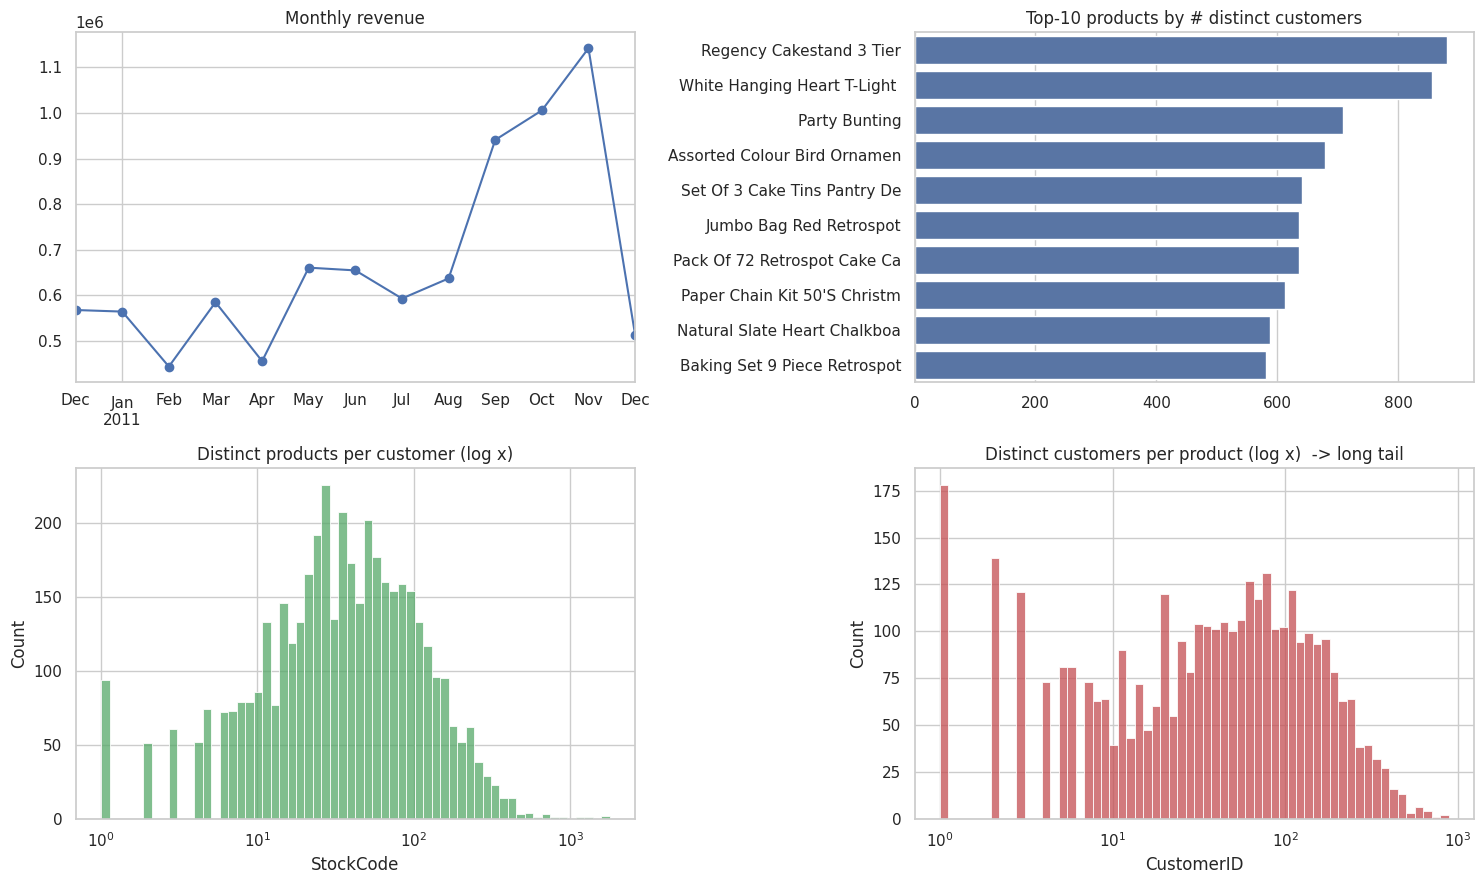

Interaction-matrix sparsity (before filtering): 98.32%


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# monthly revenue
monthly = df.groupby(df['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=ax[0, 0], marker='o')
ax[0, 0].set_title('Monthly revenue'); ax[0, 0].set_xlabel('')

# top products by number of distinct buyers
top_pop = df.groupby('StockCode')['CustomerID'].nunique().sort_values(ascending=False).head(10)
labels = [item_desc_map.get(c, c)[:28] for c in top_pop.index]
sns.barplot(x=top_pop.values, y=labels, ax=ax[0, 1], color='#4C72B0')
ax[0, 1].set_title('Top-10 products by # distinct customers')

# products bought per customer
ipc = df.groupby('CustomerID')['StockCode'].nunique()
sns.histplot(ipc, bins=60, log_scale=(True, False), ax=ax[1, 0], color='#55A868')
ax[1, 0].set_title('Distinct products per customer (log x)')

# customers per product (long tail)
cpp = df.groupby('StockCode')['CustomerID'].nunique()
sns.histplot(cpp, bins=60, log_scale=(True, False), ax=ax[1, 1], color='#C44E52')
ax[1, 1].set_title('Distinct customers per product (log x)  -> long tail')

plt.tight_layout(); plt.show()

sparsity = 1 - df[['CustomerID', 'StockCode']].drop_duplicates().shape[0] / (df.CustomerID.nunique() * df.StockCode.nunique())
print(f'Interaction-matrix sparsity (before filtering): {sparsity:.2%}')

## 5. From sales to implicit-feedback interactions

A purchase is a *positive* signal; "not purchased" does **not** mean "dislike". So we treat the problem as **implicit feedback / top-N recommendation**:

* one row per *(customer, product)* with the **first purchase time**, total quantity and number of orders,
* **5-core filtering** – keep customers with ≥ 5 products and products bought by ≥ 5 customers (removes cold-start noise).

In [ ]:
inter = (df.groupby(['CustomerID', 'StockCode'])
           .agg(first_ts=('InvoiceDate', 'min'),
                qty=('Quantity', 'sum'),
                n_orders=('InvoiceNo', 'nunique'))
           .reset_index())

def k_core(d, k_user=5, k_item=5):
    while True:
        n_before = len(d)
        ic = d['StockCode'].value_counts();  d = d[d['StockCode'].map(ic) >= k_item]
        uc = d['CustomerID'].value_counts(); d = d[d['CustomerID'].map(uc) >= k_user]
        if len(d) == n_before:
            return d.reset_index(drop=True)

inter = k_core(inter)

# integer ids for the embedding layers
inter['user'], user_ids = pd.factorize(inter['CustomerID'])
inter['item'], item_ids = pd.factorize(inter['StockCode'])
n_users, n_items = len(user_ids), len(item_ids)
user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {s: i for i, s in enumerate(item_ids)}
item_desc = np.array([item_desc_map.get(s, s) for s in item_ids])

print(f'Users: {n_users:,} | Items: {n_items:,} | Interactions: {len(inter):,}')
print(f'Density: {len(inter)/(n_users*n_items):.2%}  |  avg items/user: {len(inter)/n_users:.1f}')
inter.head()

Users: 4,074 | Items: 3,145 | Interactions: 264,510
Density: 2.06%  |  avg items/user: 64.9


,CustomerID,StockCode,first_ts,qty,n_orders,user,item
0,12347,16008,2011-04-07 10:43:00,24,1,0,0
1,12347,17021,2011-06-09 13:01:00,36,1,0,1
2,12347,20665,2011-04-07 10:43:00,6,1,0,2
3,12347,20719,2011-01-26 14:30:00,40,4,0,3
4,12347,20780,2010-12-07 14:57:00,12,1,0,4


## 6. Time-aware leave-one-out split

For every customer, interactions are ordered by first-purchase time:

* **test** = most recent product, **validation** = second most recent, **train** = everything before.

This mimics production ("predict what they buy next") and avoids look-ahead leakage.
Products bought in the same invoice share a timestamp, so ties are broken randomly.

In [ ]:
rng = np.random.default_rng(SEED)
inter['tie'] = rng.random(len(inter))
inter = inter.sort_values(['user', 'first_ts', 'tie']).reset_index(drop=True)
inter['pos_from_end'] = inter.groupby('user').cumcount(ascending=False)

test_df  = inter[inter.pos_from_end == 0]
val_df   = inter[inter.pos_from_end == 1]
train_df = inter[inter.pos_from_end >= 2]

def to_csr(d):
    return sparse.csr_matrix((np.ones(len(d), dtype=np.float32), (d.user.values, d.item.values)),
                             shape=(n_users, n_items))

R_train = to_csr(train_df)
R_val   = to_csr(val_df)
R_test  = to_csr(test_df)
R_trval = R_train + R_val          # everything known before the test item
R_all   = R_train + R_val + R_test

eval_users = np.arange(n_users)    # every user has exactly one val and one test item
val_targets  = val_df.sort_values('user')['item'].values
test_targets = test_df.sort_values('user')['item'].values
assert len(val_targets) == len(test_targets) == n_users

print(f'train: {len(train_df):,}  val: {len(val_df):,}  test: {len(test_df):,}')

# Fixed candidate sets for the "sampled" protocol: 1 true item + 99 random items the user never bought
def sample_eval_candidates(targets, n_neg=99, seed=0):
    r = np.random.default_rng(seed)
    cand = np.zeros((n_users, n_neg + 1), dtype=np.int32)
    cand[:, 0] = targets
    all_items = np.arange(n_items)
    for u in range(n_users):
        seen = R_all.indices[R_all.indptr[u]:R_all.indptr[u + 1]]
        pool = np.setdiff1d(all_items, seen, assume_unique=True)
        cand[u, 1:] = r.choice(pool, n_neg, replace=False)
    return cand

val_cand  = sample_eval_candidates(val_targets,  seed=1)
test_cand = sample_eval_candidates(test_targets, seed=2)

train: 256,362  val: 4,074  test: 4,074


## 7. Evaluation framework

Two protocols, three metrics:

* **Full ranking** (strict, realistic): rank the held-out item against *all* products the customer hasn't already bought.
* **Sampled ranking** (classic NCF paper): rank the held-out item against 99 random unseen products (easier, faster; used for early stopping).
* **HR@K** (hit-rate / recall), **NDCG@K** (rewards higher positions), **MRR**.

Every model is wrapped as `score_fn(users, items) -> scores`, so all models are evaluated by the exact same code.

In [ ]:
KS = (5, 10, 20)

def rank_of_target(scores, target_col):
    t = scores[np.arange(len(scores)), target_col][:, None]
    greater = (scores > t).sum(1)
    ties    = (scores == t).sum(1) - 1           # other items with an identical score
    return greater + ties / 2.0                  # 0-based rank, ties counted fairly

def metrics_from_ranks(ranks):
    out = {}
    for k in KS:
        hit = ranks < k
        out[f'HR@{k}']   = hit.mean()
        out[f'NDCG@{k}'] = (hit / np.log2(ranks + 2)).mean()
    out['MRR'] = (1.0 / (ranks + 1)).mean()
    return out

def evaluate_full(score_fn, users, targets, exclude, batch=256):
    ranks, all_items = [], np.arange(n_items)
    for s in range(0, len(users), batch):
        ub, tb = users[s:s + batch], targets[s:s + batch]
        items = np.tile(all_items, (len(ub), 1))
        sc = np.asarray(score_fn(ub, items), dtype=np.float32)
        sc[exclude[ub].toarray() > 0] = -np.inf     # never recommend what was already bought
        ranks.append(rank_of_target(sc, tb))
    return metrics_from_ranks(np.concatenate(ranks))

def evaluate_sampled(score_fn, users, cand, batch=1024):
    ranks = []
    for s in range(0, len(users), batch):
        ub, cb = users[s:s + batch], cand[s:s + batch]
        sc = np.asarray(score_fn(ub, cb), dtype=np.float32)
        ranks.append(rank_of_target(sc, np.zeros(len(ub), dtype=int)))
    return metrics_from_ranks(np.concatenate(ranks))

## 8. Baselines

Deep learning must be compared with something. We use two classic non-neural recommenders:

1. **Popularity** – recommend the globally most-bought products (surprisingly hard to beat in retail).
2. **Item-KNN** – cosine similarity between product purchase vectors; score = similarity to the customer's past purchases.

In [ ]:
# --- Popularity
pop = np.asarray(R_train.sum(0)).ravel().astype(np.float32)
def pop_score(users, items):
    return pop[items]

# --- Item-based KNN (cosine)
Rn  = normalize(R_train.T.tocsr(), axis=1)                 # items x users, L2-normalised rows
sim = (Rn @ Rn.T).toarray().astype(np.float32)
np.fill_diagonal(sim, 0)
knn_scores = np.asarray(R_train @ sim, dtype=np.float32)   # users x items
def knn_score(users, items):
    return knn_scores[users[:, None], items]

results = {}
for name, fn in [('Popularity', pop_score), ('Item-KNN', knn_score)]:
    results[name] = {
        **{f'full_{k}': v    for k, v in evaluate_full(fn, eval_users, test_targets, R_trval).items()},
        **{f'sampled_{k}': v for k, v in evaluate_sampled(fn, eval_users, test_cand).items()},
    }
pd.DataFrame(results).T[['full_HR@10', 'full_NDCG@10', 'sampled_HR@10', 'sampled_NDCG@10']].round(4)

,full_HR@10,full_NDCG@10,sampled_HR@10,sampled_NDCG@10
Popularity,0.0329,0.0154,0.3841,0.2014
Item-KNN,0.1379,0.0798,0.5643,0.3658


## 9. Deep model – Neural Collaborative Filtering (NeuMF)

[He et al., 2017](https://arxiv.org/abs/1708.05031) fuse two learners:

* **GMF** (Generalised Matrix Factorisation): element-wise product of user & item embeddings → linear-style interaction.
* **MLP**: concatenated user & item embeddings passed through a stack of dense layers → non-linear interaction.

Both are concatenated and fed to a sigmoid unit that outputs *P(customer buys product)*.

```
user ─┬─ GMF emb ─┐                       ┌─ GMF (⊙) ─────────┐
      └─ MLP emb ─┼─ concat → Dense(64) → Dense(32) → Dense(16) ─┼─ concat → Dense(1, σ)
item ─┬─ GMF emb ─┘                       └───────────────────┘
      └─ MLP emb ─┘
```

**Training:** binary cross-entropy with **negative sampling** – for every real purchase we sample 4 random *unbought* products as negatives, re-sampled each epoch. Early stopping uses validation NDCG@10.

In [ ]:
def build_neumf(n_users, n_items, mf_dim=32, mlp_dim=32, mlp_units=(64, 32, 16), dropout=0.2, l2=1e-6):
    reg = regularizers.l2(l2)
    u_in = keras.Input(shape=(), dtype='int32', name='user')
    i_in = keras.Input(shape=(), dtype='int32', name='item')

    # GMF branch
    gu = layers.Embedding(n_users, mf_dim, embeddings_regularizer=reg, name='gmf_user_emb')(u_in)
    gi = layers.Embedding(n_items, mf_dim, embeddings_regularizer=reg, name='gmf_item_emb')(i_in)
    gmf = layers.Multiply(name='gmf_product')([gu, gi])

    # MLP branch
    mu = layers.Embedding(n_users, mlp_dim, embeddings_regularizer=reg, name='mlp_user_emb')(u_in)
    mi = layers.Embedding(n_items, mlp_dim, embeddings_regularizer=reg, name='mlp_item_emb')(i_in)
    x = layers.Concatenate(name='mlp_concat')([mu, mi])
    for k, units in enumerate(mlp_units):
        x = layers.Dense(units, activation='relu', kernel_regularizer=reg, name=f'mlp_dense_{k}')(x)
        x = layers.Dropout(dropout, name=f'mlp_drop_{k}')(x)

    z = layers.Concatenate(name='fusion')([gmf, x])
    out = layers.Dense(1, activation='sigmoid', name='purchase_prob')(z)
    return keras.Model([u_in, i_in], out, name='NeuMF')

model = build_neumf(n_users, n_items)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
model.summary()

Model: "NeuMF"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ item (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_user_emb        │ (None, 32)        │    130,368 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_item_emb        │ (None, 32)        │    100,640 │ item[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_concat          │ (None, 64)        │          0 │ mlp_user_emb[0][… │
│ (Concatenate)       │                   │            │ mlp_item_emb[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dense_0 (Dense) │ (None, 64)        │      4,160 │ mlp_concat[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_drop_0          │ (None, 64)        │          0 │ mlp_dense_0[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dense_1 (Dense) │ (None, 32)        │      2,080 │ mlp_drop_0[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_drop_1          │ (None, 32)        │          0 │ mlp_dense_1[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gmf_user_emb        │ (None, 32)        │    130,368 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gmf_item_emb        │ (None, 32)        │    100,640 │ item[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_dense_2 (Dense) │ (None, 16)        │        528 │ mlp_drop_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gmf_product         │ (None, 32)        │          0 │ gmf_user_emb[0][… │
│ (Multiply)          │                   │            │ gmf_item_emb[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mlp_drop_2          │ (None, 16)        │          0 │ mlp_dense_2[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion              │ (None, 48)        │          0 │ gmf_product[0][0… │
│ (Concatenate)       │                   │            │ mlp_drop_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ purchase_prob       │ (None, 1)         │         49 │ fusion[0][0]      │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 468,833 (1.79 MB)

 Trainable params: 468,833 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ---- negative sampling for the training set (re-drawn every epoch)
train_u = train_df['user'].values.astype(np.int32)
train_i = train_df['item'].values.astype(np.int32)
pos_keys = np.sort(train_u.astype(np.int64) * n_items + train_i)
neg_rng = np.random.default_rng(SEED)

def sample_training_set(n_neg=4):
    users = np.repeat(train_u, n_neg)
    items = neg_rng.integers(0, n_items, size=len(users)).astype(np.int32)
    bad = np.isin(users.astype(np.int64) * n_items + items, pos_keys)
    while bad.any():                                    # resample accidental positives
        items[bad] = neg_rng.integers(0, n_items, size=bad.sum())
        bad = np.isin(users.astype(np.int64) * n_items + items, pos_keys)
    U = np.concatenate([train_u, users])
    I = np.concatenate([train_i, items])
    y = np.concatenate([np.ones(len(train_u)), np.zeros(len(users))]).astype(np.float32)
    p = neg_rng.permutation(len(U))
    return U[p], I[p], y[p]

# ---- wrap the model as a score_fn(users, items) -> (batch, m) matrix
def neumf_score(users, items):
    b, m = items.shape
    u = np.repeat(users, m).astype(np.int32)
    i = items.reshape(-1).astype(np.int32)
    p = model.predict({'user': u, 'item': i}, batch_size=65536, verbose=0)
    return p.reshape(b, m)

epoch 01 | loss 0.4492 | val HR@10 0.3814 | val NDCG@10 0.1991  <-- best
epoch 02 | loss 0.4130 | val HR@10 0.4578 | val NDCG@10 0.2526  <-- best
epoch 03 | loss 0.3777 | val HR@10 0.5248 | val NDCG@10 0.3035  <-- best
epoch 04 | loss 0.3515 | val HR@10 0.5655 | val NDCG@10 0.3357  <-- best
epoch 05 | loss 0.3324 | val HR@10 0.5830 | val NDCG@10 0.3492  <-- best
epoch 06 | loss 0.3181 | val HR@10 0.5930 | val NDCG@10 0.3623  <-- best
epoch 07 | loss 0.3058 | val HR@10 0.6058 | val NDCG@10 0.3699  <-- best
epoch 08 | loss 0.2951 | val HR@10 0.6048 | val NDCG@10 0.3728  <-- best
epoch 09 | loss 0.2859 | val HR@10 0.6105 | val NDCG@10 0.3764  <-- best
epoch 10 | loss 0.2783 | val HR@10 0.6129 | val NDCG@10 0.3801  <-- best
epoch 11 | loss 0.2712 | val HR@10 0.6178 | val NDCG@10 0.3822  <-- best
epoch 12 | loss 0.2661 | val HR@10 0.6141 | val NDCG@10 0.3822  <-- best
epoch 13 | loss 0.2608 | val HR@10 0.6188 | val NDCG@10 0.3867  <-- best
epoch 14 | loss 0.2567 | val HR@10 0.6188 | val NDC

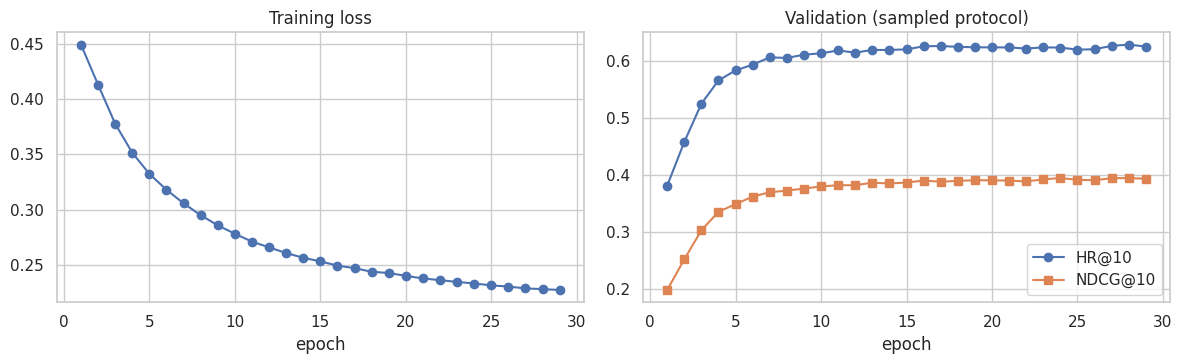

In [ ]:
EPOCHS, PATIENCE, N_NEG, BATCH = 40, 5, 4, 2048

best_ndcg, best_weights, wait = -1.0, None, 0
history = []

for ep in range(1, EPOCHS + 1):
    U, I, y = sample_training_set(N_NEG)
    loss = model.fit({'user': U, 'item': I}, y, batch_size=BATCH, epochs=1, verbose=0).history['loss'][0]
    m = evaluate_sampled(neumf_score, eval_users, val_cand)
    history.append({'epoch': ep, 'loss': loss, 'val_HR@10': m['HR@10'], 'val_NDCG@10': m['NDCG@10']})
    flag = ''
    if m['NDCG@10'] > best_ndcg:
        best_ndcg, best_weights, wait, flag = m['NDCG@10'], model.get_weights(), 0, '  <-- best'
    else:
        wait += 1
    print(f"epoch {ep:02d} | loss {loss:.4f} | val HR@10 {m['HR@10']:.4f} | val NDCG@10 {m['NDCG@10']:.4f}{flag}")
    if wait >= PATIENCE:
        print(f'Early stopping (no improvement for {PATIENCE} epochs).')
        break

model.set_weights(best_weights)
hist = pd.DataFrame(history)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hist.epoch, hist.loss, marker='o'); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(hist.epoch, hist['val_HR@10'], marker='o', label='HR@10')
ax[1].plot(hist.epoch, hist['val_NDCG@10'], marker='s', label='NDCG@10')
ax[1].set_title('Validation (sampled protocol)'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

## 10. Final results on the held-out test items

Best-validation weights are restored; test metrics are computed once.
In the **full-ranking** protocol the model must find the next product among *all* unseen products (~3–4k) – the number that matters for a real shop.

,full_HR@5,full_NDCG@5,full_HR@10,full_NDCG@10,full_HR@20,full_NDCG@20,full_MRR
Popularity,0.0172,0.0103,0.0329,0.0154,0.0552,0.0210,0.0163
Item-KNN,0.0947,0.0659,0.1379,0.0798,0.1851,0.0917,0.0714
NeuMF,0.0724,0.0484,0.1163,0.0626,0.1804,0.0787,0.0577


,sampled_HR@5,sampled_NDCG@5,sampled_HR@10,sampled_NDCG@10,sampled_HR@20,sampled_NDCG@20,sampled_MRR
Popularity,0.2430,0.1563,0.3841,0.2014,0.5731,0.2490,0.1707
Item-KNN,0.4411,0.3261,0.5643,0.3658,0.7018,0.4003,0.3220
NeuMF,0.4688,0.3432,0.6235,0.3931,0.7734,0.4310,0.3391


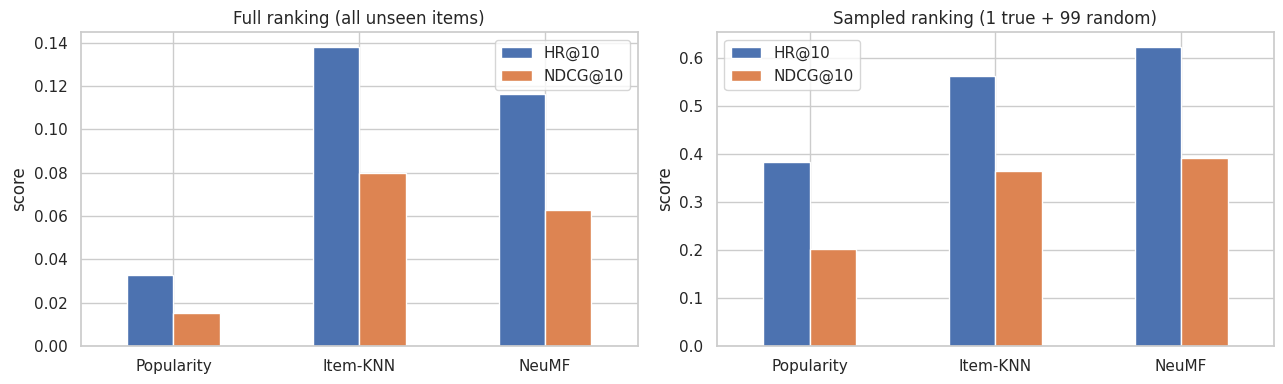

In [ ]:
results['NeuMF'] = {
    **{f'full_{k}': v    for k, v in evaluate_full(neumf_score, eval_users, test_targets, R_trval, batch=128).items()},
    **{f'sampled_{k}': v for k, v in evaluate_sampled(neumf_score, eval_users, test_cand).items()},
}
res = pd.DataFrame(results).T
display(res[[c for c in res.columns if c.startswith('full_')]].round(4))
display(res[[c for c in res.columns if c.startswith('sampled_')]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, proto, title in zip(ax, ['full', 'sampled'], ['Full ranking (all unseen items)', 'Sampled ranking (1 true + 99 random)']):
    res[[f'{proto}_HR@10', f'{proto}_NDCG@10']].rename(columns=lambda c: c.replace(f'{proto}_', '')).plot.bar(ax=a, rot=0)
    a.set_title(title); a.set_ylabel('score')
plt.tight_layout(); plt.show()

**How to read this**

* Retail data is dominated by a popular head, so *Popularity* is a strong baseline and Item-KNN is often very competitive – this is well documented in the recommender-systems literature. A neural model earns its place if it matches/beats them in **full ranking**, and it scales better once you add side information (product text, prices, time, sequences).
* The sampled protocol is optimistic (random negatives are easy) – always trust the full-ranking numbers more.
* Results vary a little between runs / hardware because of random initialisation and negative sampling. If your NeuMF numbers are lower than expected, try the tuning ideas in the last section.

## 11. Using the recommender

### 11.1 Top-N recommendations for a customer

In [ ]:
def purchase_history(customer_id, n=8):
    u = user2idx[customer_id]
    h = inter[inter.user == u].sort_values('qty', ascending=False).head(n)
    return pd.DataFrame({'StockCode': h.StockCode.values, 'Product': item_desc[h.item.values],
                         'Total qty bought': h.qty.values})

def recommend(customer_id, n=10):
    u = user2idx[customer_id]
    items = np.arange(n_items)[None, :]
    scores = neumf_score(np.array([u]), items)[0]
    scores[R_all[u].indices] = -np.inf                       # hide products already bought
    top = np.argsort(-scores)[:n]
    return pd.DataFrame({'Rank': range(1, n + 1), 'StockCode': item_ids[top],
                         'Product': item_desc[top], 'P(buy)': scores[top].round(3)})

demo_customer = int(user_ids[0])
print(f'Customer {demo_customer} - most-bought products so far:')
display(purchase_history(demo_customer))
print(f'Top-10 recommendations for customer {demo_customer}:')
display(recommend(demo_customer))

Customer 12347 - most-bought products so far:


,StockCode,Product,Total qty bought
0,23076,Ice Cream Sundae Lip Gloss,240
1,84558A,3D Dog Picture Playing Cards,126
2,22492,Mini Paint Set Vintage,108
3,23084,Rabbit Night Light,84
4,22196,Small Heart Measuring Spoons,72
5,84991,60 Teatime Fairy Cake Cases,72
6,21731,Red Toadstool Led Night Light,72
7,84992,72 Sweetheart Fairy Cake Cases,72


Top-10 recommendations for customer 12347:


,Rank,StockCode,Product,P(buy)
0,1,22993,Set Of 4 Pantry Jelly Moulds,0.971
1,2,22996,Travel Card Wallet Vintage Ticket,0.954
2,3,15060B,Fairy Cake Design Umbrella,0.953
3,4,22659,Lunch Box I Love London,0.942
4,5,22963,Jam Jar With Green Lid,0.939
5,6,22962,Jam Jar With Pink Lid,0.935
6,7,22998,Travel Card Wallet Keep Calm,0.931
7,8,22966,Gingerbread Man Cookie Cutter,0.910
8,9,23154,Set Of 4 Jam Jar Magnets,0.910
9,10,22907,Pack Of 20 Napkins Pantry Design,0.901


### 11.2 "Customers also buy" – similar products from the learned item embeddings

In [ ]:
item_emb = np.concatenate([model.get_layer('gmf_item_emb').get_weights()[0],
                           model.get_layer('mlp_item_emb').get_weights()[0]], axis=1)
item_emb = item_emb / np.linalg.norm(item_emb, axis=1, keepdims=True)

def find_item(keyword, n=10):
    m = pd.Series(item_desc).str.contains(keyword, case=False, regex=False)
    return pd.DataFrame({'StockCode': item_ids[m.values][:n], 'Product': item_desc[m.values][:n]})

def similar_items(stock_code, n=8):
    i = item2idx[stock_code]
    s = item_emb @ item_emb[i]
    s[i] = -np.inf
    top = np.argsort(-s)[:n]
    return pd.DataFrame({'StockCode': item_ids[top], 'Product': item_desc[top], 'Similarity': s[top].round(3)})

seed_item = item_ids[int(np.argmax(pop))]                     # the most popular product
print('Products most similar to:', item_desc[item2idx[seed_item]])
display(similar_items(seed_item))

# try your own search:  find_item('lunch bag')

Products most similar to: Regency Cakestand 3 Tier


,StockCode,Product,Similarity
0,23245,Set Of 3 Regency Cake Tins,0.739
1,22699,Roses Regency Teacup And Saucer,0.720
2,22697,Green Regency Teacup And Saucer,0.634
3,23173,Regency Teapot Roses,0.634
4,23170,Regency Tea Plate Roses,0.628
5,47566,Party Bunting,0.618
6,22698,Pink Regency Teacup And Saucer,0.617
7,22969,Homemade Jam Scented Candles,0.615


## 12. Save the trained model and mappings

In [ ]:
model.save('neumf_recommender.keras')
with open('recsys_artifacts.pkl', 'wb') as f:
    pickle.dump({'user_ids': user_ids, 'item_ids': item_ids, 'item_desc': item_desc}, f)
print('Saved: neumf_recommender.keras, recsys_artifacts.pkl')

# To download to your computer:
# from google.colab import files
# files.download('neumf_recommender.keras'); files.download('recsys_artifacts.pkl')

Saved: neumf_recommender.keras, recsys_artifacts.pkl
